In [ ]:
 # Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
# Load the dataset
df = pd.read_csv("/content/archive (4).zip")
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group D,some college,standard,completed,59,70,78
1,male,group D,associate's degree,standard,none,96,93,87
2,female,group D,some college,free/reduced,none,57,76,77
3,male,group B,some college,free/reduced,none,70,70,63
4,female,group D,associate's degree,standard,none,83,85,86


In [ ]:
df.isnull().sum()


,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [ ]:
df.columns = df.columns.str.replace(" ", "_")


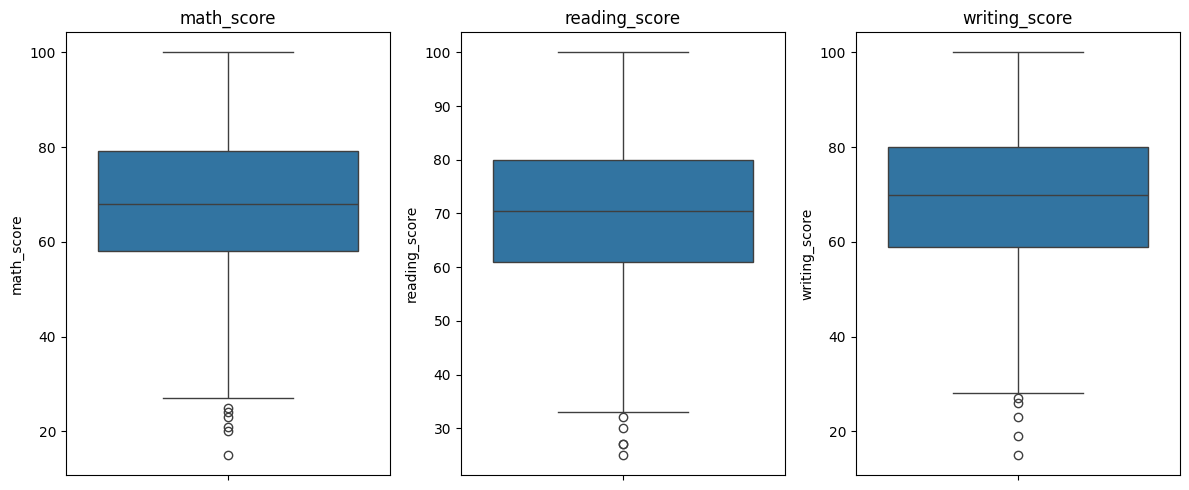

In [ ]:
# Visualize boxplots for numerical features
plt.figure(figsize=(12, 5))
for i, col in enumerate(['math_score', 'reading_score', 'writing_score']):
    plt.subplot(1, 3, i+1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()


In [ ]:
# Encode categorical features using LabelEncoder
df_encoded = df.copy()
categorical_cols = ['gender', 'race/ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le


In [ ]:
# Feature scaling
features = df_encoded.drop('math_score', axis=1)
target = df_encoded['math_score']

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(features_scaled, target, test_size=0.2, random_state=42)


In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [ ]:
# Display coefficients
feature_names = features.columns
coefficients = model.coef_
intercept = model.intercept_

coef_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefficients})
print(coef_df)


                       Feature  Coefficient
0                       gender     6.358245
1               race/ethnicity     0.985244
2  parental_level_of_education    -0.075904
3                        lunch     2.124598
4      test_preparation_course     1.809043
5                reading_score     4.466458
6                writing_score     9.515423


In [ ]:
# Predictions
y_pred = model.predict(X_test)

# Metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"R-squared: {r2:.2f}")


Mean Squared Error: 26.01
Mean Absolute Error: 4.22
R-squared: 0.88


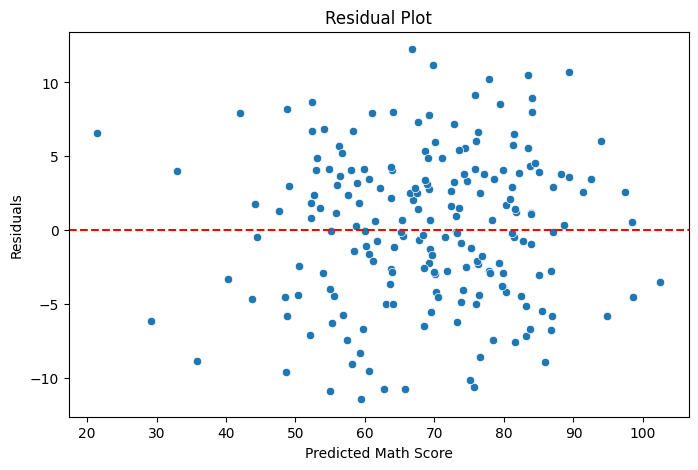

In [ ]:
# Residuals
residuals = y_test - y_pred

# Plot
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Math Score")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


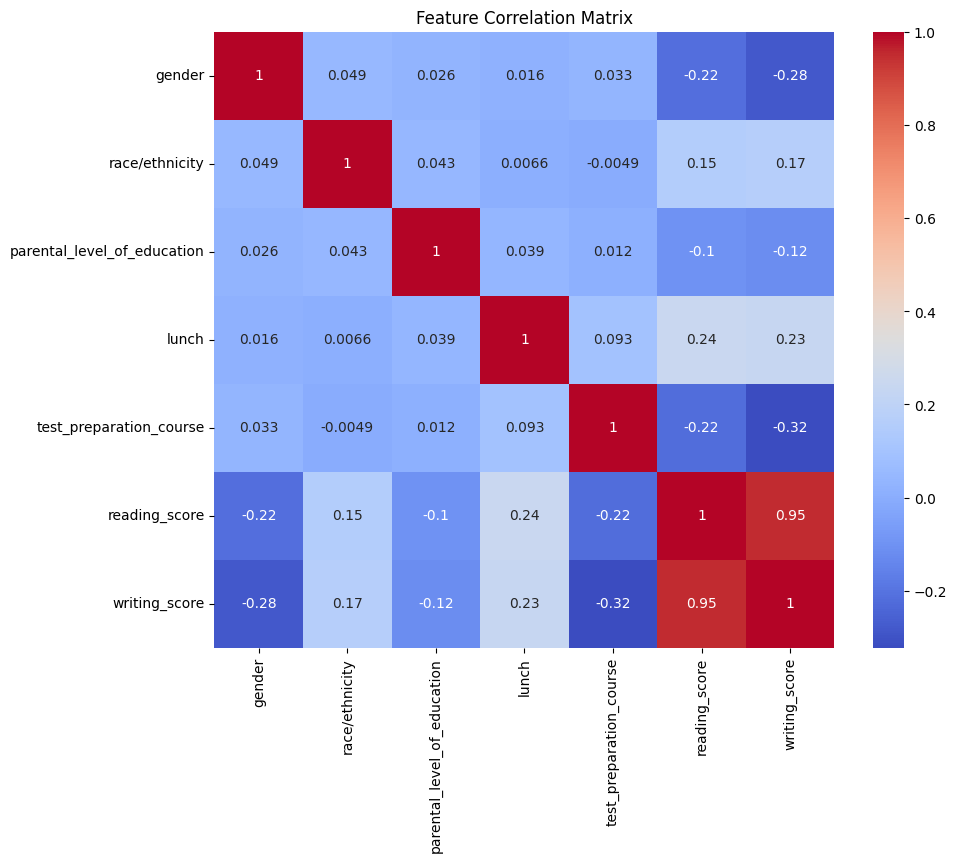

In [ ]:
# Correlation matrix
corr_matrix = pd.DataFrame(features_scaled, columns=feature_names).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Feature Correlation Matrix")
plt.show()
